# Fixation Order Analysis

The question is whether the ordered VLM priority points match the temporal order of human fixations, beyond the same points with their order shuffled. The main metric is scasim similarity, adopted from https://github.com/tmalsburg/scanpath/blob/master/scanpath/R/scanpath.R

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import pathlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy import stats

ANALYSIS = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
REPO = ANALYSIS.parent

sys.path.insert(0, str(ANALYSIS))

from helpers import runs as R
from helpers import util as U

COCO = REPO / "data" / "COCO-Search18"
RNG_SEED = 0

print("repo:", REPO)

repo: /path/to/VLM-goal-directed-attention


## Target cells

This fixation-order analysis uses target-absent images, the output arm, and all available val plus scaleup runs. Search-prompt model order is compared to human search scanpaths; free-view-prompt model order is compared to human free-view scanpaths.

In [3]:
condition = "ta"
arm = "output"
models = ["qwen-thinking", "gemma"]
goals = ["search", "free"]

run_rows = []
for model in models:
    for goal in goals:
        run_ids = U.get_run_ids(model, condition, arm, goal)
        run_rows.append({
            "model": model,
            "model_label": R.MODEL_LABEL[model],
            "condition": condition,
            "arm": arm,
            "goal": goal,
            "run_ids": run_ids,
        })

order_runs = pd.DataFrame(run_rows)
order_runs

,model,model_label,condition,arm,goal,run_ids
0,qwen-thinking,Qwen3-VL-32B-Thinking,ta,output,search,"[58031597, 58094212]"
1,qwen-thinking,Qwen3-VL-32B-Thinking,ta,output,free,"[58031679, 58094237]"
2,gemma,Gemma-4-26B-A4B-it,ta,output,search,"[57202063, 58387153]"
3,gemma,Gemma-4-26B-A4B-it,ta,output,free,"[57707609, 57707610, 57707611, 57707612, 57707..."


## Load model and human scanpaths

Model scanpaths come from `points_<run>.csv`, grouped by sampled sequence and ordered by `rank`. Human search scanpaths come from COCO-Search18 target-absent trials; human free-view scanpaths come from COCO-FreeView trials for the same image names. `U.load_human_scanpaths` applies the same letterbox crop and drops the forced central start fixation.

In [4]:
model_scanpaths = {
    (row.model, row.goal): U.load_model_scanpaths(row.run_ids, max_rank=R.FROZEN_TOPN)
    for row in order_runs.itertuples(index=False)
}
image_keys = sorted({image_key for scanpaths in model_scanpaths.values() for image_key in scanpaths})
human_scanpaths = U.load_human_scanpaths(COCO, image_keys, goals=goals)

for key, scanpaths in model_scanpaths.items():
    print(key, "images:", len(scanpaths))

('qwen-thinking', 'search') images: 2416
('qwen-thinking', 'free') images: 2416
('gemma', 'search') images: 2365
('gemma', 'free') images: 2416


## scasim order metric

For each image, the notebook computes two scasim-inspired similarities:

- `floor`: model scanpath points with their order shuffled, compared to human scanpaths
- `model`: ordered model scanpaths compared to human scanpaths

The order effect is `model - floor`. The paired test compares ordered model similarity against its order-shuffled floor across images.

Note: this implementation follows the original scasim dynamic-programming recurrence, but uses a simplified version tailored to these data. It treats all fixations as unit duration and approximates visual angle with Euclidean pixel distance divided by `pixels_per_degree`. The original R implementation uses fixation durations, duration-weighted gap/substitution costs, and angular distances after inverse gnomonic projection. Therefore, the metric here should be read as a scasim-inspired order similarity rather than a full port of the original `scasim` function.


In [5]:
DVA_WIDTH = 30.0
MODULATOR = 0.83
TRUNCATE = R.FROZEN_TOPN
N_SHUFFLE = 5
MAX_MODEL_SCANPATHS = 8


def scasim(scanpath_a, scanpath_b, pixels_per_degree, modulator=MODULATOR):
    """Continuous scasim dissimilarity with unit fixation durations."""
    n_fixations_a, n_fixations_b = len(scanpath_a), len(scanpath_b)
    distance = np.empty((n_fixations_a + 1, n_fixations_b + 1))
    distance[:, 0] = np.arange(n_fixations_a + 1)
    distance[0, :] = np.arange(n_fixations_b + 1)

    for i in range(n_fixations_a):
        for j in range(n_fixations_b):
            spatial_distance = np.hypot(
                scanpath_a[i, 0] - scanpath_b[j, 0],
                scanpath_a[i, 1] - scanpath_b[j, 1],
            ) / pixels_per_degree
            substitution_cost = 2.0 * (1.0 - modulator ** spatial_distance)
            distance[i + 1, j + 1] = min(
                distance[i, j + 1] + 1.0,
                distance[i + 1, j] + 1.0,
                distance[i, j] + substitution_cost,
            )

    return distance[n_fixations_a, n_fixations_b]


def scasim_similarity(scanpath_a, scanpath_b, pixels_per_degree):
    """Convert scasim dissimilarity into the paper's per-pair similarity scale."""
    normalizer = 2.0 * max(len(scanpath_a), len(scanpath_b))
    return 1.0 - scasim(scanpath_a, scanpath_b, pixels_per_degree) / normalizer


def score_model_order_cell(model, goal, random_seed=RNG_SEED):
    """Compute per-image model and order-shuffled floor scasim similarities."""
    rng = np.random.default_rng(random_seed)
    rows = []

    for task, name in sorted(model_scanpaths[(model, goal)]):
        image_human_scanpaths, (cropped_width, cropped_height) = human_scanpaths[goal].get((task, name), ([], (0, 0)))
        image_human_scanpaths = [scanpath[:TRUNCATE] for scanpath in image_human_scanpaths if len(scanpath)]
        pixels_per_degree = max(cropped_width, cropped_height) / DVA_WIDTH

        if len(image_human_scanpaths) < 2:
            continue

        image_model_scanpaths = [
            scanpath[:TRUNCATE]
            for scanpath in model_scanpaths[(model, goal)][(task, name)][:MAX_MODEL_SCANPATHS]
            if len(scanpath)
        ]
        if not image_model_scanpaths:
            continue

        model_similarity = np.mean([
            scasim_similarity(model_scanpath, human_scanpath, pixels_per_degree)
            for model_scanpath in image_model_scanpaths
            for human_scanpath in image_human_scanpaths
        ])
        shuffled_similarity = np.mean([
            scasim_similarity(rng.permutation(model_scanpath), human_scanpath, pixels_per_degree)
            for model_scanpath in image_model_scanpaths
            for _ in range(N_SHUFFLE)
            for human_scanpath in image_human_scanpaths
        ])
        rows.append({
            "model": model,
            "model_label": R.MODEL_LABEL[model],
            "goal": goal,
            "task": task,
            "name": name,
            "floor": shuffled_similarity,
            "model_similarity": model_similarity,
            "order_effect": model_similarity - shuffled_similarity,
        })

    return pd.DataFrame(rows)

In [6]:
order_results = pd.concat(
    [score_model_order_cell(model, goal) for model in models for goal in goals],
    ignore_index=True,
)

order_results.head()

,model,model_label,goal,task,name,floor,model_similarity,order_effect
0,qwen-thinking,Qwen3-VL-32B-Thinking,search,bottle,000000000196.jpg,0.334819,0.351328,0.016510
1,qwen-thinking,Qwen3-VL-32B-Thinking,search,bottle,000000003992.jpg,0.393116,0.392206,-0.000910
2,qwen-thinking,Qwen3-VL-32B-Thinking,search,bottle,000000005522.jpg,0.440342,0.439099,-0.001243
3,qwen-thinking,Qwen3-VL-32B-Thinking,search,bottle,000000005600.jpg,0.446143,0.449420,0.003277
4,qwen-thinking,Qwen3-VL-32B-Thinking,search,bottle,000000009866.jpg,0.457061,0.477286,0.020225


## Model order effects

The order-effect test uses a repeated-measures `model × goal` ANOVA on `model_similarity - floor`, followed by paired search-vs-free comparisons within each model.

In [7]:
order_anova_data = order_results.copy()
order_anova_data["picture"] = order_anova_data["task"] + " / " + order_anova_data["name"]

complete_pictures = (
    order_anova_data
    .groupby("picture")[["model", "goal"]]
    .apply(lambda cells: cells.drop_duplicates().shape[0])
)
complete_pictures = complete_pictures[complete_pictures == len(models) * len(goals)].index
order_anova_data = order_anova_data[order_anova_data["picture"].isin(complete_pictures)].reset_index(drop=True)

order_anova_data["model"] = pd.Categorical(order_anova_data["model"], categories=models, ordered=True)
order_anova_data["goal"] = pd.Categorical(order_anova_data["goal"], categories=goals, ordered=True)

order_summary = (
    order_anova_data
    .groupby(["model", "goal"], observed=True)
    .agg(
        n_images=("picture", "nunique"),
        floor_mean=("floor", "mean"),
        model_mean=("model_similarity", "mean"),
        order_effect_mean=("order_effect", "mean"),
        order_effect_sd=("order_effect", "std"),
        percent_model_above_floor=("order_effect", lambda values: 100 * (values > 0).mean()),
    )
    .reset_index()
)

print("Complete pictures for 2 x 2 ANOVA:", len(complete_pictures))
order_summary

Complete pictures for 2 x 2 ANOVA: 2326


,model,goal,n_images,floor_mean,model_mean,order_effect_mean,order_effect_sd,percent_model_above_floor
0,qwen-thinking,search,2326,0.425318,0.425179,-0.000139,0.015595,49.183147
1,qwen-thinking,free,2326,0.340237,0.347931,0.007693,0.017862,66.981943
2,gemma,search,2326,0.417600,0.420114,0.002514,0.016047,57.910576
3,gemma,free,2326,0.334354,0.341586,0.007231,0.016869,67.626827


## 2 x 2 ANOVA

Run a repeated-measures ANOVA with `model` and `goal` on the per-image order effect.

In [8]:
order_rmanova = pg.rm_anova(
    data=order_anova_data,
    dv="order_effect",
    within=["model", "goal"],
    subject="picture",
    detailed=True,
)

order_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,model,0.002792,1,2325,0.002792,17.755003,2.608452e-05,2.608452e-05,0.001086,1.0
1,goal,0.091578,1,2325,0.091578,235.521957,1.046667e-50,1.046667e-50,0.034438,1.0
2,model * goal,0.005642,1,2325,0.005642,37.349648,1.154421e-09,1.154421e-09,0.002192,1.0


## Paired Comparisons

Compare search vs free-view order effects separately for each model.

In [9]:
pairwise_results = []

for model, model_data in order_anova_data.groupby("model", observed=True, sort=False):
    paired_goals = (
        model_data
        .pivot(index="picture", columns="goal", values="order_effect")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    pairwise_results.append(
        {
            "model": model,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

order_pairwise_tests = pd.DataFrame(pairwise_results)
order_pairwise_tests[
    ["model", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,model,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,qwen-thinking,search,free,-16.028466,2325,two-sided,6.351975e-55,0.467111,-0.009,-0.007
1,gemma,search,free,-9.934997,2325,two-sided,8.291008e-23,0.286531,-0.006,-0.004


## Plot

A split violin shows the per-image order-effect distributions for search and free-view within each model. The palette is intentionally distinct from the 2 x 2 dissociation plots.

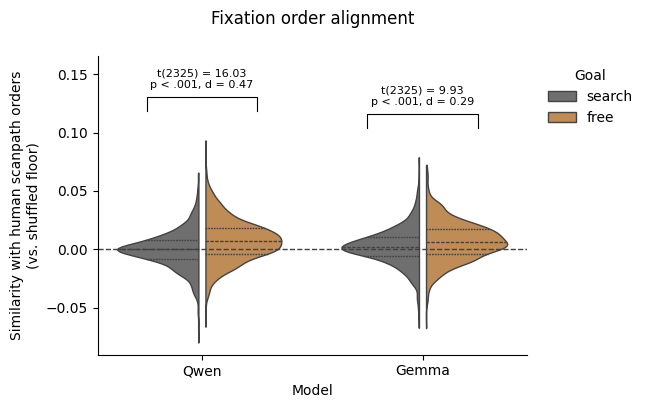

In [10]:
plot_data = order_anova_data.copy()
plot_data["model_label"] = plot_data["model"].map({
    "qwen-thinking": "Qwen",
    "gemma": "Gemma",
})
plot_data["goal_label"] = plot_data["goal"].map({
    "search": "search",
    "free": "free",
})

model_order = ["Qwen", "Gemma"]
goal_order = ["search", "free"]
order_palette = {"search": "#6f6f6f", "free": "#d08c45"}

fig, ax = plt.subplots(figsize=(6.6, 4.2))
sns.violinplot(
    data=plot_data,
    x="model_label",
    y="order_effect",
    hue="goal_label",
    order=model_order,
    hue_order=goal_order,
    palette=order_palette,
    split=True,
    gap=0.08,
    inner="quartile",
    cut=0,
    linewidth=1,
    ax=ax,
)


annotation_top = plot_data["order_effect"].max()
annotation_step = 0.035
model_name_to_label = {"qwen-thinking": "Qwen", "gemma": "Gemma"}
x_positions = np.arange(len(model_order))

for model_index, model_label in enumerate(model_order):
    model_name = {value: key for key, value in model_name_to_label.items()}[model_label]
    pairwise_row = order_pairwise_tests[order_pairwise_tests["model"] == model_name].iloc[0]

    x_left = x_positions[model_index] - 0.25
    x_right = x_positions[model_index] + 0.25
    y_base = plot_data.loc[
        plot_data["model_label"] == model_label,
        "order_effect",
    ].max() + 0.025
    y_top = y_base + 0.012

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.006,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.axhline(0, color="0.25", linewidth=1, linestyle="--")
ax.set_xlabel("Model")
ax.set_ylabel("Similarity with human scanpath orders\n(vs. shuffled floor)")
ax.set_title("Fixation order alignment", y=1.08)
ax.set_ylim(top=annotation_top)
ax.legend(title="Goal", frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
sns.despine(ax=ax)
plt.tight_layout()

## Center-Out Fixation Order

Eccentricity is each fixation's distance from image center, normalized by the center-to-corner distance of the cropped image. Model scanpaths are pooled across Qwen and Gemma.

In [11]:
def normalized_eccentricity(points, image_size):
    """Distance from image center, normalized by the center-to-corner distance."""
    cropped_width, cropped_height = image_size
    center = np.array([cropped_width / 2, cropped_height / 2])
    max_distance = np.hypot(cropped_width / 2, cropped_height / 2)
    return np.linalg.norm(points - center, axis=1) / max_distance


def scanpath_eccentricity_rows(scanpath, image_key, image_size, source, goal, max_fixations=R.FROZEN_TOPN):
    """Return one row per fixation with normalized eccentricity."""
    task, name = image_key
    eccentricity = normalized_eccentricity(scanpath[:max_fixations], image_size)
    return [
        {
            "source": source,
            "goal": goal,
            "task": task,
            "name": name,
            "picture": f"{task} / {name}",
            "fixation_index": fixation_index + 1,
            "eccentricity": value,
        }
        for fixation_index, value in enumerate(eccentricity)
    ]


eccentricity_rows = []

for goal in goals:
    for image_key, (image_human_scanpaths, image_size) in human_scanpaths[goal].items():
        for scanpath in image_human_scanpaths:
            eccentricity_rows.extend(
                scanpath_eccentricity_rows(scanpath, image_key, image_size, "Human", goal)
            )

    for model in models:
        for image_key, image_model_scanpaths in model_scanpaths[(model, goal)].items():
            image_size = human_scanpaths[goal].get(image_key, ([], None))[1]
            if image_size is None:
                continue

            for scanpath in image_model_scanpaths:
                eccentricity_rows.extend(
                    scanpath_eccentricity_rows(scanpath, image_key, image_size, "Model", goal)
                )

eccentricity_by_fixation = pd.DataFrame(eccentricity_rows)
eccentricity_by_fixation.head()

,source,goal,task,name,picture,fixation_index,eccentricity
0,Human,search,bottle,000000000196.jpg,bottle / 000000000196.jpg,1,0.100253
1,Human,search,bottle,000000000196.jpg,bottle / 000000000196.jpg,2,0.114270
2,Human,search,bottle,000000000196.jpg,bottle / 000000000196.jpg,3,0.387187
3,Human,search,bottle,000000000196.jpg,bottle / 000000000196.jpg,4,0.531757
4,Human,search,bottle,000000000196.jpg,bottle / 000000000196.jpg,5,0.579000


## First-Fixation Eccentricity ANOVA

Aggregate first-fixation eccentricity to one value per picture for each `source × goal` cell, then run a repeated-measures ANOVA.

In [12]:
first_fixation_anova_data = (
    eccentricity_by_fixation[eccentricity_by_fixation["fixation_index"] == 1]
    .groupby(["picture", "source", "goal"], observed=True)
    .agg(eccentricity=("eccentricity", "mean"))
    .reset_index()
)

complete_pictures = (
    first_fixation_anova_data
    .groupby("picture")[["source", "goal"]]
    .apply(lambda cells: cells.drop_duplicates().shape[0])
)
complete_pictures = complete_pictures[complete_pictures == 4].index
first_fixation_anova_data = first_fixation_anova_data[
    first_fixation_anova_data["picture"].isin(complete_pictures)
].reset_index(drop=True)

first_fixation_anova_data["source"] = pd.Categorical(
    first_fixation_anova_data["source"],
    categories=["Human", "Model"],
    ordered=True,
)
first_fixation_anova_data["goal"] = pd.Categorical(
    first_fixation_anova_data["goal"],
    categories=goals,
    ordered=True,
)

first_fixation_summary = (
    first_fixation_anova_data
    .groupby(["source", "goal"], observed=True)
    .agg(
        n_images=("picture", "nunique"),
        mean_eccentricity=("eccentricity", "mean"),
        sd_eccentricity=("eccentricity", "std"),
    )
    .reset_index()
)

print("Complete pictures for first-fixation 2 x 2 ANOVA:", len(complete_pictures))
first_fixation_summary

Complete pictures for first-fixation 2 x 2 ANOVA: 2413


,source,goal,n_images,mean_eccentricity,sd_eccentricity
0,Human,search,2413,0.313929,0.088231
1,Human,free,2413,0.247780,0.068316
2,Model,search,2413,0.463151,0.174557
3,Model,free,2413,0.321610,0.149332


## First-Fixation 2 x 2 ANOVA

In [13]:
first_fixation_rmanova = pg.rm_anova(
    data=first_fixation_anova_data,
    dv="eccentricity",
    within=["source", "goal"],
    subject="picture",
    detailed=True,
)

first_fixation_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,source,30.012910,1,2412,30.012910,2617.389924,0.000000e+00,0.000000e+00,0.160215,1.0
1,goal,26.021088,1,2412,26.021088,1148.135805,3.423077e-206,3.423077e-206,0.141931,1.0
2,source * goal,3.428865,1,2412,3.428865,275.798518,9.957376e-59,9.957376e-59,0.021331,1.0


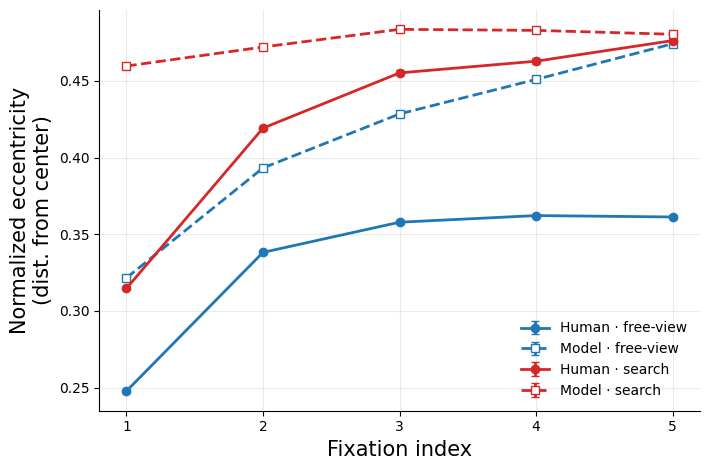

In [17]:
center_out_plot_data = (
    eccentricity_by_fixation
    .groupby(["source", "goal", "fixation_index"], observed=True)
    .agg(
        mean_eccentricity=("eccentricity", "mean"),
        se_eccentricity=("eccentricity", lambda values: values.std(ddof=1) / np.sqrt(len(values))),
    )
    .reset_index()
)

line_specs = [
    ("Human", "free", "#1f77b4", "o", "-", "Human · free-view"),
    ("Model", "free", "#1f77b4", "s", "--", "Model · free-view"),
    ("Human", "search", "#d62728", "o", "-", "Human · search"),
    ("Model", "search", "#d62728", "s", "--", "Model · search"),
]

fig, ax = plt.subplots(figsize=(7.2, 4.8))

for source, goal, color, marker, linestyle, label in line_specs:
    line_data = center_out_plot_data[
        (center_out_plot_data["source"] == source)
        & (center_out_plot_data["goal"] == goal)
    ].sort_values("fixation_index")

    ax.errorbar(
        line_data["fixation_index"],
        line_data["mean_eccentricity"],
        yerr=line_data["se_eccentricity"],
        color=color,
        marker=marker,
        markerfacecolor="white" if source == "Model" else color,
        markeredgecolor=color,
        linestyle=linestyle,
        linewidth=2,
        markersize=6,
        capsize=3,
        label=label,
    )

ax.set_xticks(range(1, R.FROZEN_TOPN + 1))
ax.set_xlabel("Fixation index", fontsize=15)
ax.set_ylabel("Normalized eccentricity\n(dist. from center)", fontsize=15)
ax.grid(True, alpha=0.25)
ax.legend(frameon=False, loc="lower right")
sns.despine(ax=ax)
plt.tight_layout()